In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:

# 1. Read your existing Parquet outputs
output_path = Path("/home/azureuser/EBRD_Tillage/data/output").expanduser()
df = pd.concat([pd.read_parquet(f) for f in output_path.glob("**/*.parquet")])
df.head()

,field_id,point_id,item_id,datetime,date,mgrs_tile,eo_cloud_cover,platform,pixel_col,pixel_row,...,SCL,OCM_CLASS,s2_processing_baseline,s2_processing_baseline_value,s2_baseline_harmonized,s2_baseline_offset_applied,valid_px,lon,lat,spatial_batch_id
0,1.0,1.0_80_3,S2A_MSIL2A_20201001T084801_R107_T36UWB_2020100...,2020-10-01T08:48:01.024000Z,2020-10-01,36UWB,71.952178,Sentinel-2A,80,3,...,8.0,2,02.12,2.12,False,0,False,34.101113,50.896789,1
1,1.0,1.0_81_3,S2A_MSIL2A_20201001T084801_R107_T36UWB_2020100...,2020-10-01T08:48:01.024000Z,2020-10-01,36UWB,71.952178,Sentinel-2A,81,3,...,8.0,2,02.12,2.12,False,0,False,34.101255,50.896788,1
2,1.0,1.0_82_3,S2A_MSIL2A_20201001T084801_R107_T36UWB_2020100...,2020-10-01T08:48:01.024000Z,2020-10-01,36UWB,71.952178,Sentinel-2A,82,3,...,8.0,2,02.12,2.12,False,0,False,34.101398,50.896787,1
3,1.0,1.0_83_3,S2A_MSIL2A_20201001T084801_R107_T36UWB_2020100...,2020-10-01T08:48:01.024000Z,2020-10-01,36UWB,71.952178,Sentinel-2A,83,3,...,8.0,2,02.12,2.12,False,0,False,34.101540,50.896785,1
4,1.0,1.0_84_3,S2A_MSIL2A_20201001T084801_R107_T36UWB_2020100...,2020-10-01T08:48:01.024000Z,2020-10-01,36UWB,71.952178,Sentinel-2A,84,3,...,8.0,2,02.12,2.12,False,0,False,34.101682,50.896784,1


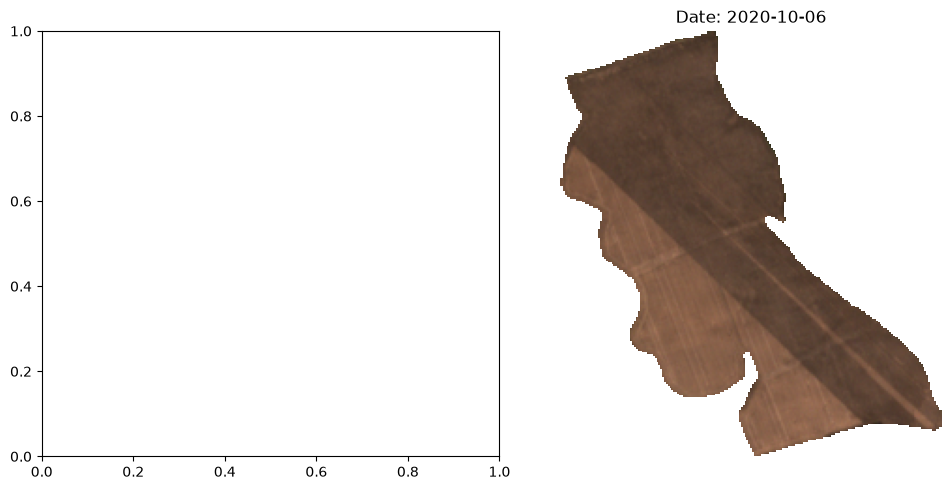

In [4]:

# 2. Group by acquisition date and pivot to grid
dates = df["date"].unique()
fig, axes = plt.subplots(nrows=1, ncols=len(dates), figsize=(5 * len(dates), 5))

if len(dates) == 1:
    axes = [axes]

for ax, date in zip(axes, dates):
    scene_df = df[(df["date"] == date) & (df["valid_px"] == True)]
    
    if scene_df.empty:
        continue
        
    # Pivot spatial coordinates into 2D raster grids
    grid_r = scene_df.pivot(index="pixel_row", columns="pixel_col", values="B4")
    grid_g = scene_df.pivot(index="pixel_row", columns="pixel_col", values="B3")
    grid_b = scene_df.pivot(index="pixel_row", columns="pixel_col", values="B2")
    
    # Stack and scale reflectance for display (scale factor ~ 3000)
    rgb = np.dstack([grid_r.values, grid_g.values, grid_b.values]) / 3000.0
    rgb = np.clip(rgb, 0, 1) # Clip values between 0 and 1
    
    ax.imshow(rgb)
    ax.set_title(f"Date: {date}")
    ax.axis("off")

plt.tight_layout()
plt.show()